In [104]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [105]:
import pandas as pd
df= pd.read_csv("/content/drive/MyDrive/CSE475/lung_disease.xlsx - Sheet1.csv")
print(df.to_string())

         Patient smoke   FVC   FEC1 PEFR O2 ABG-P-O2 ABG-P-CO2 ABG-pH Level   Scan Asthama Other diseaes  AGE Risk
0      Patient-1     T  2.85   2.16    F  F        F         T            T  X-ray       F             F   60    F
1      Patient-2     F  3.40   1.88    F  F        F         F            F    MRI       T             F   51    F
2      Patient-3     F  2.76   2.08    F  F        F         T            F  X-ray       F             F   59    F
3      Patient-4     F  3.68   3.04    F  F        F         F            F  X-ray       F             F   54    F
4      Patient-5     F  2.44   0.96    F  T        F         T            T  X-ray       F             F   73    T
5      Patient-6     F  2.48   1.88    F  F        F         T            F  X-ray       F             F   51    F
6      Patient-7     F  4.36   3.28    F  F        F         T            F    MRI       T             F   59    T
7      Patient-8     F  3.19   2.50    F  F        F         T            F  X-r

In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error,classification_report
from sklearn.linear_model import LinearRegression

In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 470 entries, 0 to 469
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Patient        470 non-null    object 
 1   smoke          470 non-null    object 
 2   FVC            470 non-null    float64
 3   FEC1           470 non-null    float64
 4   PEFR           470 non-null    object 
 5   O2             470 non-null    object 
 6   ABG-P-O2       470 non-null    object 
 7   ABG-P-CO2      470 non-null    object 
 8   ABG-pH Level   470 non-null    object 
 9   Scan           470 non-null    object 
 10  Asthama        470 non-null    object 
 11  Other diseaes  470 non-null    object 
 12  AGE            470 non-null    int64  
 13  Risk           470 non-null    object 
dtypes: float64(2), int64(1), object(11)
memory usage: 51.5+ KB


In [108]:
# Display Head and Tail
print("Head:")
print(df.head())
print("Tail:")
print(df.tail())

Head:
     Patient smoke   FVC  FEC1 PEFR O2 ABG-P-O2 ABG-P-CO2 ABG-pH Level   Scan  \
0  Patient-1     T  2.85  2.16    F  F        F         T            T  X-ray   
1  Patient-2     F  3.40  1.88    F  F        F         F            F    MRI   
2  Patient-3     F  2.76  2.08    F  F        F         T            F  X-ray   
3  Patient-4     F  3.68  3.04    F  F        F         F            F  X-ray   
4  Patient-5     F  2.44  0.96    F  T        F         T            T  X-ray   

  Asthama Other diseaes  AGE Risk  
0       F             F   60    F  
1       T             F   51    F  
2       F             F   59    F  
3       F             F   54    F  
4       F             F   73    T  
Tail:
         Patient smoke   FVC  FEC1 PEFR O2 ABG-P-O2 ABG-P-CO2 ABG-pH Level  \
465  Patient-466     F  3.88  2.12    F  F        F         T            F   
466  Patient-467     F  3.76  3.12    F  F        F         F            F   
467  Patient-468     F  3.04  2.08    F  F        F

In [109]:
# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Patient          0
smoke            0
FVC              0
FEC1             0
PEFR             0
O2               0
ABG-P-O2         0
ABG-P-CO2        0
ABG-pH Level     0
Scan             0
Asthama          0
Other diseaes    0
AGE              0
Risk             0
dtype: int64


In [110]:
# Check for duplicate values
print("\nNumber of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


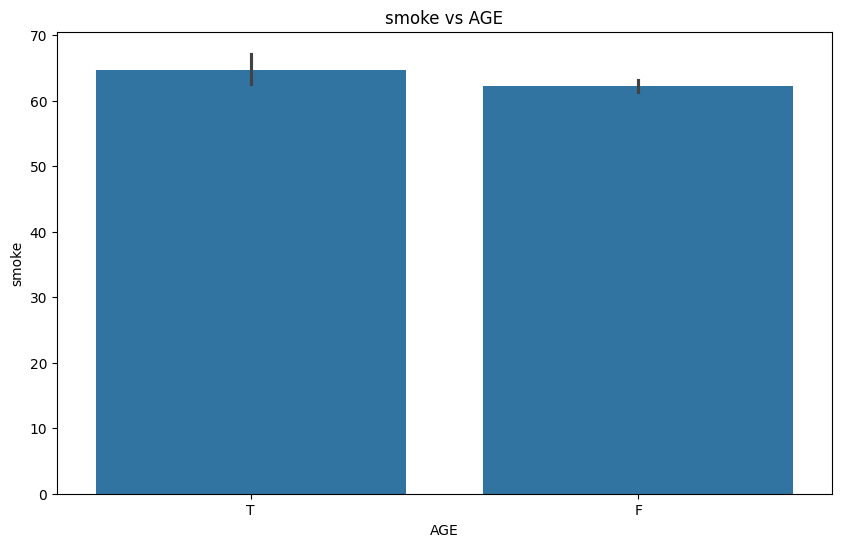

In [111]:
#Barchart
plt.figure(figsize=(10,6))
sns.barplot(x=df['smoke'],y=df['AGE'])
plt.xlabel('AGE')
plt.ylabel('smoke')
plt.title('smoke vs AGE')
plt.show()

/tmp/ipython-input-3591183943.py:4: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x=df['AGE'],y=df['FVC'], palette='coolwarm')


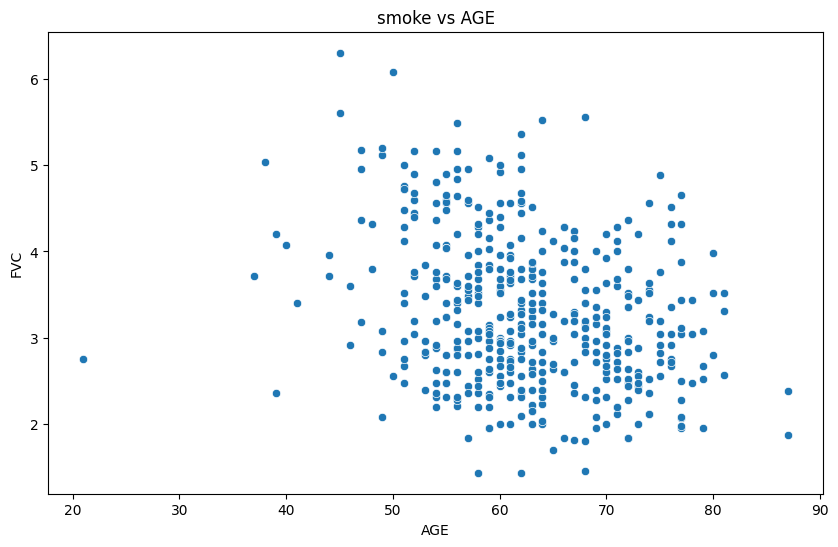

In [112]:
#Scatterplot
plt.figure(figsize=(10,6))
plt.title('smoke vs AGE')
sns.scatterplot(x=df['AGE'],y=df['FVC'], palette='coolwarm')
plt.xlabel('AGE')
plt.ylabel('FVC')
plt.show()

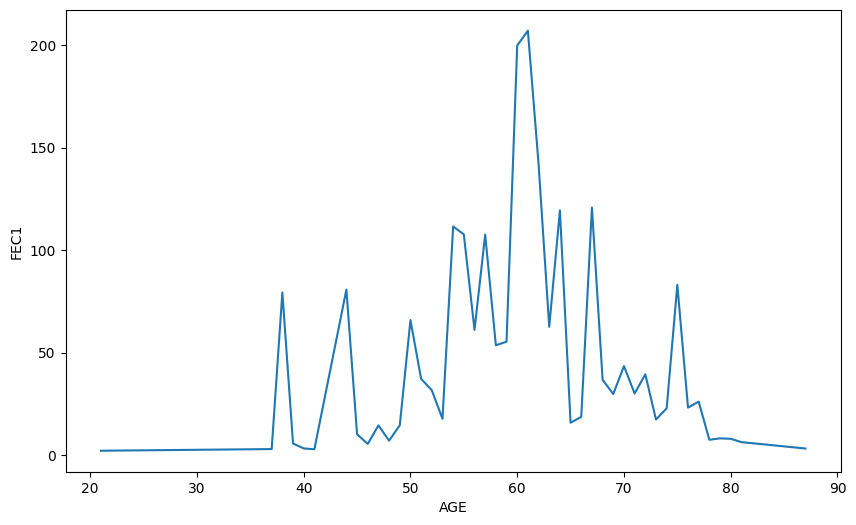

In [113]:
#Linechart
plt.figure(figsize=(10, 6))
df.groupby('AGE')['FEC1'].sum().plot()
plt.xlabel('AGE')
plt.ylabel('FEC1')
plt.show()

In [114]:
# Define the mapping dictionary

smoke_mapping = {
    'T': 1,
    'F': 2,
}

# Apply the mapping
df['smoke'] = df['smoke'].map(smoke_mapping)




# Define the mapping dictionary
PEFR_mapping = {
    'T': 3,
    'F': 4,
}

# Apply the mapping
df['PEFR'] = df['PEFR'].map(PEFR_mapping)





# Define the mapping dictionary
ABG_P_O2_mapping = {
    'T': 5,
    'F': 6,
}

# Apply the mapping
df['ABG-P-O2'] = df['ABG-P-O2'].map(ABG_P_O2_mapping)




# Define the mapping dictionary
ABG_P_CO2_mapping = {
    'T': 7,
    'F': 8,
}

# Apply the mapping
df['ABG-P-CO2'] = df['ABG-P-CO2'].map(ABG_P_CO2_mapping)





# Define the mapping dictionary
O2_mapping = {
    'T': 1,
    'F': 2,
}

# Apply the mapping
df['O2'] = df['O2'].map(O2_mapping)




# Define the mapping dictionary
ABG_pH_Level_mapping = {
    'T': 1,
    'F': 2,
}

# Apply the mapping
df['ABG-pH Level'] = df['ABG-pH Level'].map(ABG_pH_Level_mapping)





# Define the mapping dictionary
Asthama_mapping = {
    'T': 1,
    'F': 2,
}

# Apply the mapping
df['Asthama'] = df['Asthama'].map(Asthama_mapping)





# Define the mapping dictionary
Scan_mapping = {
    'X-ray': 1,
    'MRI': 2,
    'CT': 3,
}

# Apply the mapping
df['Scan'] = df['Scan'].map(Scan_mapping)




# Define the mapping dictionary
Risk_mapping = {
    'T': 1,
    'F': 2,
}

# Apply the mapping
df['Risk'] = df['Risk'].map(Risk_mapping)




# Define the mapping dictionary
Other_diseaes_mapping = {
    'T': 1,
    'F': 2,
}

# Apply the mapping
df['Other diseaes'] = df['Other diseaes'].map(Other_diseaes_mapping)

In [115]:
print(df.to_string())

         Patient  smoke   FVC   FEC1  PEFR  O2  ABG-P-O2  ABG-P-CO2  ABG-pH Level  Scan  Asthama  Other diseaes  AGE  Risk
0      Patient-1      1  2.85   2.16     4   2         6          7             1     1        2              2   60     2
1      Patient-2      2  3.40   1.88     4   2         6          8             2     2        1              2   51     2
2      Patient-3      2  2.76   2.08     4   2         6          7             2     1        2              2   59     2
3      Patient-4      2  3.68   3.04     4   2         6          8             2     1        2              2   54     2
4      Patient-5      2  2.44   0.96     4   1         6          7             1     1        2              2   73     1
5      Patient-6      2  2.48   1.88     4   2         6          7             2     1        2              2   51     2
6      Patient-7      2  4.36   3.28     4   2         6          7             2     2        1              2   59     1
7      Patient-8

In [116]:
df.drop(columns=['Patient'],inplace=True)

In [117]:
print(df.to_string())

     smoke   FVC   FEC1  PEFR  O2  ABG-P-O2  ABG-P-CO2  ABG-pH Level  Scan  Asthama  Other diseaes  AGE  Risk
0        1  2.85   2.16     4   2         6          7             1     1        2              2   60     2
1        2  3.40   1.88     4   2         6          8             2     2        1              2   51     2
2        2  2.76   2.08     4   2         6          7             2     1        2              2   59     2
3        2  3.68   3.04     4   2         6          8             2     1        2              2   54     2
4        2  2.44   0.96     4   1         6          7             1     1        2              2   73     1
5        2  2.48   1.88     4   2         6          7             2     1        2              2   51     2
6        2  4.36   3.28     4   2         6          7             2     2        1              2   59     1
7        2  3.19   2.50     4   2         6          7             2     1        2              2   66     1
8        1

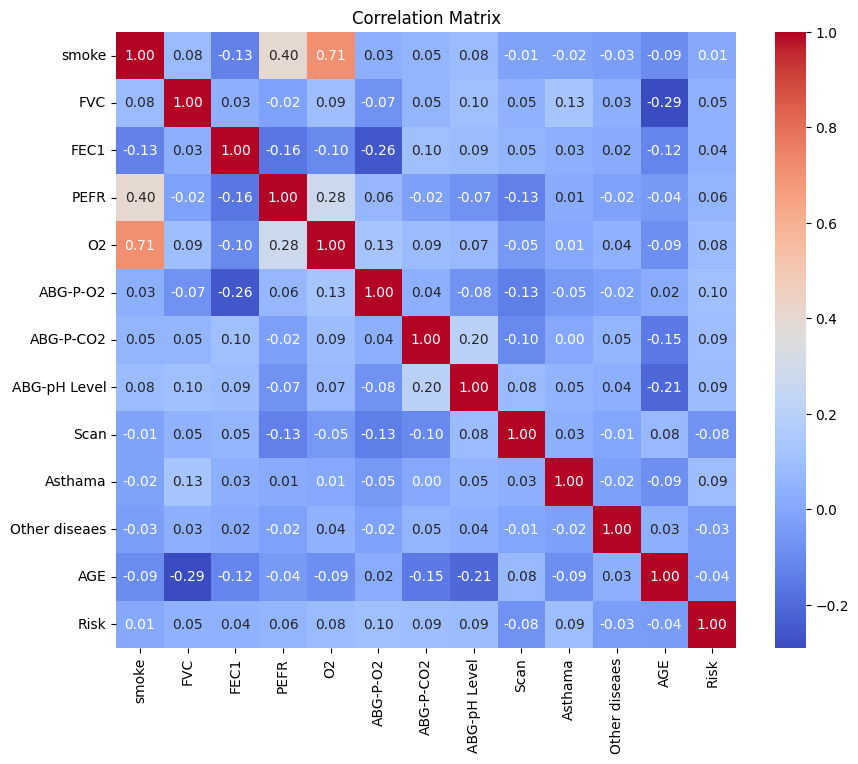

In [120]:
# Correlation matrix
correlation_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [121]:
X=df.drop(columns=['Risk'])
Y=df['Risk']

In [122]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [123]:
from sklearn.linear_model import LogisticRegression

In [124]:
model = LogisticRegression()

model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [125]:
y_pred = model.predict(X_test)

print(y_pred)

[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [126]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Calculate precision
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

# Calculate recall (sensitivity)
recall = recall_score(y_test, y_pred)
print("Recall (Sensitivity):", recall)

# Calculate F1-score
f1 = f1_score(y_test, y_pred)
print("F1-Score:", f1)

Accuracy: 0.7978723404255319
Precision: 0.0
Recall (Sensitivity): 0.0
F1-Score: 0.0


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


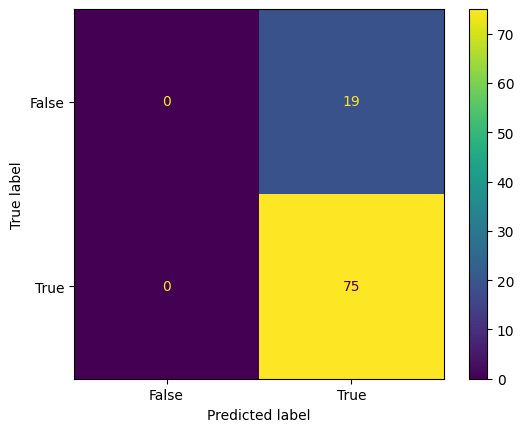

In [127]:
#confuison matrix for titanic dataset
import matplotlib.pyplot as plt
from sklearn import metrics
confusion_matrix = metrics.confusion_matrix(y_test,y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [False, True])
cm_display.plot()
plt.show()